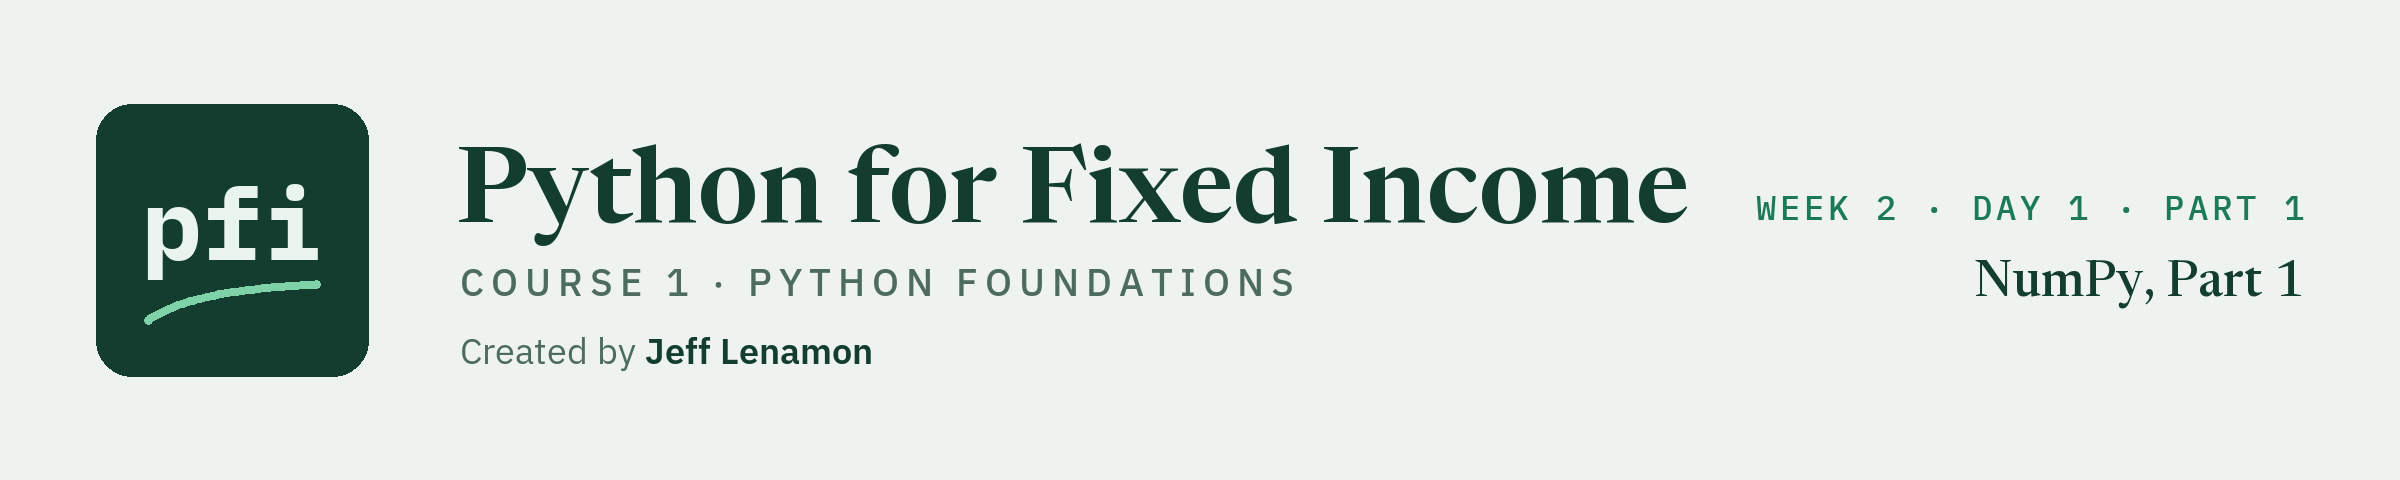

# NumPy, Part 1

Week 2, Day 1, Part 1. Doing arithmetic on a whole column of bonds in one step.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day1/06_numpy.ipynb)

## Before You Start: Install the Libraries

Run this cell first.

It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab.

If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course01_python_foundations/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "nbformat": "nbformat==5.11.1",
    "nltk": "nltk==3.10.3",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "plotly": "plotly==7.1.0",
    "pytest": "pytest==9.1.1",
    "seaborn": "seaborn==0.13.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

11 packages checked, all present


In week 1 the credit desk kept each column of its holdings in a list and worked through it with a loop: one bond at a time, a running total, a few lines of bookkeeping for every question.

That is fine for four bonds.

The desk's questions are nearly always about the whole column at once: the cost of every position, the yield on every bond, the weighted average of the book.

**NumPy** is the Python library built for that.

Its main structure, the **array**, holds a column of numbers and lets us calculate on all of them in a single line. pandas, the library behind the table you built on Day 5 of week 1, is built on top of it.

We use the same four bonds as in week 1.

The issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Maturity</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Face held</th></tr>
<tr><td align="left">QVNE</td><td align="left">5.25</td><td align="left">2033</td><td align="left">98.50</td><td align="left">BBB</td><td align="left">9</td><td align="left">1,500,000</td></tr>
<tr><td align="left">DNMR</td><td align="left">6.125</td><td align="left">2034</td><td align="left">103.25</td><td align="left">BB+</td><td align="left">11</td><td align="left">500,000</td></tr>
<tr><td align="left">PLWK</td><td align="left">4.75</td><td align="left">2031</td><td align="left">95.00</td><td align="left">A-</td><td align="left">7</td><td align="left">750,000</td></tr>
<tr><td align="left">HLVF</td><td align="left">7.50</td><td align="left">2032</td><td align="left">101.00</td><td align="left">B+</td><td align="left">14</td><td align="left">250,000</td></tr>
</table>
<br clear="left">

The score is the desk's rating score from week 1: AAA is 1 and each notch lower adds one.

A score of 10 or lower is investment grade, and 11 or higher is high yield.

## 6.1 Why Arrays

Let's start with the lists from week 1.

In [2]:
ticker_list = ['QVNE', 'DNMR', 'PLWK', 'HLVF']
coupon_list = [5.25, 6.125, 4.75, 7.5]
price_list = [98.5, 103.25, 95.0, 101.0]
face_list = [1500000, 500000, 750000, 250000]

Q. What did each of the four positions cost? The cost of a position is its face times its price, divided by 100. Can we multiply the two lists?

In [3]:
# try to multiply the face of every bond by its price
face_list * price_list

TypeError: can't multiply sequence by non-int of type 'list'

A `TypeError`: can't multiply sequence by non-int of type 'list'.

A list is a container.

It holds numbers, but it does not do arithmetic with them.

The message hints that a list can be multiplied by a whole number.

Let's see what that does.

**Predict 1**

We want to double every price, and the next cell multiplies the list by 2:

```
print(price_list * 2)
```

What do you expect it to print?

> A) The four prices, each doubled: 197.0, 206.5, 190.0, and 202.0.
>
> B) Eight prices: the same four, twice over.
>
> C) A `TypeError`, as before.

Decide, then run the cell.

In [4]:
# multiply the list by 2
print(price_list * 2)

[98.5, 103.25, 95.0, 101.0, 98.5, 103.25, 95.0, 101.0]


The answer is B. There is no error, and it is not what we asked for.

The list was repeated: eight prices where we had four, and none of them doubled.

For a list, `*` means 'repeat'.

This is the more dangerous of the two results.

The first one stopped us.

This one ran and handed back something that looks like data.

**Predict 2**

This morning's prices and this afternoon's prices for two bonds are in two lists, and the next cell puts a `+` between them:

```
morning_prices = [98.5, 103.25]
afternoon_prices = [98.75, 103.0]
print(morning_prices + afternoon_prices)
```

What do you expect it to print?

> A) Two sums: 197.25 and 206.25.
>
> B) One list of four prices.
>
> C) A `TypeError`.

Decide, then run the cell.

In [5]:
# put a + between the two lists
morning_prices = [98.5, 103.25]
afternoon_prices = [98.75, 103.0]
print(morning_prices + afternoon_prices)

[98.5, 103.25, 98.75, 103.0]


The answer is B: one list of four prices.

We did not get 197.25 and 206.25.

For a list, `+` means 'join' and `*` means 'repeat'.

Both treat the list as a container and ignore the numbers inside it.

In week 1 we solved this with a loop.

In [6]:
# start with an empty list, then work out one position at a time
cost_list = []
for face, price in zip(face_list, price_list):
    cost_list.append(face * price / 100)

print(cost_list)

[1477500.0, 516250.0, 712500.0, 252500.0]


The loop works.

It also takes four lines to say 'face times price over 100'.

NumPy lets us say exactly that.

It is a library, as pandas is.

The install cell at the top of this notebook took care of Step 1 from Day 0, so only Step 2 is left: the import.

Q. Import NumPy.

In [7]:
# as with pandas and pd, np is the short name every NumPy user gives it
import numpy as np

Q. Convert the face and price lists to arrays, and work out the cost of every position.

In [8]:
# np.array() converts a list to a NumPy array
faces = np.array(face_list)
prices = np.array(price_list)

# one line of arithmetic covers all four bonds
costs = faces * prices / 100
print(costs)

[1477500.  516250.  712500.  252500.]


1,477,500, then 516,250, 712,500, and 252,500: the same four costs the loop produced.

The dot after each number is how NumPy prints a float: `516250.` is 516250.0.

With arrays, `*` means multiply.

The first face is multiplied by the first price, the second by the second, and so on down the column.

**Excel side by side.** This is what filling a formula down a column does.

With face in column B and price in column C, `=B2*C2/100` filled down four rows gives the same four costs.

In Microsoft 365 and Excel 2021, typing `=B2:B5*C2:C5/100` in one cell spills the four costs down the column, which is the closer match to the NumPy line.

## 6.2 Creating Arrays

Q. What is the data type of **prices**, and how does it print?

In [9]:
# check the data type
print(type(prices))
# print the array
print(prices)

<class 'numpy.ndarray'>
[ 98.5  103.25  95.   101.  ]


The type is `numpy.ndarray`, short for n-dimensional array.

An array prints with square brackets like a list, but with spaces between the values and no commas.

That is the quick way to tell the two apart in an output.

Q. Create arrays for the tickers, the coupons, and the rating scores.

In [10]:
# an array can be made from a list variable or from a list typed in place
tickers = np.array(ticker_list)
coupons = np.array(coupon_list)
scores = np.array([9, 11, 7, 14])

print(tickers)
print(coupons)
print(scores)

['QVNE' 'DNMR' 'PLWK' 'HLVF']
[5.25  6.125 4.75  7.5  ]
[ 9 11  7 14]


NumPy lines the numbers up to the same width, so 5.25 and 7.5 print with extra spaces.

The values are unchanged.

A list can hold a mix of types.

An array holds one type only, and that is part of what makes it quick.

The type of the values is stored in the attribute `dtype`.

Q. What type of value does each array hold?

In [11]:
# dtype is the type of the values inside the array
print('coupons:', coupons.dtype)
print('faces:', faces.dtype)
print('tickers:', tickers.dtype)

coupons: float64
faces: int64
tickers: <U4


`float64` is a float and `int64` is a whole number.

The 64 is the memory each value uses: 64 binary digits, called bits, which is 8 bytes.

`<U4` reads in three pieces.

`U` stands for Unicode, the standard way of storing text.

`4` means up to 4 characters, the length of our longest ticker.

`<` is a detail of how the computer orders the bytes, and you can ignore it.

What happens if a list with mixed types is converted to an array?

In [12]:
# a ticker and its coupon in one list
mixed = np.array(['QVNE', 5.25])
print(mixed)
print(mixed.dtype)

['QVNE' '5.25']
<U32


There is no error.

NumPy made everything text so that the array has one type, and the coupon is now the string '5.25'.

No arithmetic can be done on it.

The rule for this course: one array per column, as in a spreadsheet.

Numbers in one array, tickers in another.

Q. How many bonds are in the **prices** array, and how many dimensions does it have?

In [13]:
# size is the number of values
print('Size:', prices.size)
# ndim is the number of dimensions
print('Dimensions:', prices.ndim)
# shape is the length along each dimension
print('Shape:', prices.shape)

Size: 4
Dimensions: 1
Shape: (4,)


The array holds 4 values, in 1 dimension.

The array is a single column of data.

The shape `(4,)` is a tuple with one item, the length.

The comma after the 4 is how Python writes a tuple that holds one item.

Arrays do not have to come from a list.

NumPy has functions that build common patterns directly.

Q. A trader wants a run of prices from 95 to 105, one point apart.

In [14]:
# np.arange(start, stop, step) counts from start up to, but not including, stop
price_run = np.arange(95, 106, 1)
print(price_run)

[ 95  96  97  98  99 100 101 102 103 104 105]


`np.arange()` works like `range()` from Day 1 of week 1 and returns an array.

The stop value is left out, so we stop at 106 to get 105 as the last price.

**Excel side by side.** In Microsoft 365 and Excel 2021, `=SEQUENCE(11, 1, 95, 1)` spills the same 11 prices down a column: 11 rows, 1 column, starting at 95, with a step of 1.

Q. QVNE pays a coupon every six months for the next 7 years. Build the payment times in years: 0.5, 1.0, and so on up to 7.0.

In [15]:
# unlike range(), np.arange() accepts a step with a decimal point
payment_times = np.arange(0.5, 7.5, 0.5)
print(payment_times)
print('Number of payments:', payment_times.size)

[0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5.  5.5 6.  6.5 7. ]
Number of payments: 14


14 payment times, from half a year to 7 years.

Seven years of semiannual coupons is 14 payments.

Q. Build the same time grid by giving the first time, the last time, and the number of payments.

In [16]:
# np.linspace(start, stop, count) returns count evenly spaced values, including both ends
print(np.linspace(0.5, 7, 14))

[0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5.  5.5 6.  6.5 7. ]


The same 14 values.

Use `np.arange()` when you know the step, and `np.linspace()` when you know how many points you want.

`np.linspace()` includes the stop value.

A decimal step has a trap in it, and it comes from the way decimals are stored, as `0.1 + 0.2` showed on Day 3 of week 1.

**Predict 3**

The next cell counts from 1 up to, but not including, 1.3, in steps of 0.1:

```
print(np.arange(1, 1.3, 0.1))
```

What is the last number it prints?

> A) 1.2, because the stop value is left out.
>
> B) 1.3.

Decide, then run the cell.

In [17]:
# 1.3 is the stop, so it should be left out
print(np.arange(1, 1.3, 0.1))

[1.  1.1 1.2 1.3]


The answer is B. The stop value came back in: the last number is 1.3.

Rounding inside the computer put the count of steps a hair above 3, so NumPy returned a fourth value.

A step of 0.5 is stored exactly, so the 14-payment grid above is safe.

For a step such as 0.1, use `np.linspace()`, which is told the count.

Q. The desk wants a column of zeros to hold the accrued interest of each of the four bonds, to be filled in later.

In [18]:
# np.zeros(n) returns an array of n zeros
accrued = np.zeros(4)
print(accrued)

[0. 0. 0. 0.]


Q. Every bond in the portfolio redeems at 100. Build an array of the four redemption values.

In [19]:
# np.ones(n) returns an array of n ones. Multiply to get any constant.
redemptions = np.ones(4) * 100
print(redemptions)

[100. 100. 100. 100.]


`np.zeros()` and `np.ones()` create arrays of a given length filled with one value.

An array of ones times a number is a quick way to get a constant column.

## 6.3 Arithmetic on Whole Arrays

An operation applied to every value of an array at once is called a **vectorized** operation.

The cost calculation in section 6.1 was the first one.

Q. Every price in the portfolio rises by half a point. What are the new prices?

In [20]:
# a single number is applied to every value in the array
print(prices + 0.5)

[ 99.   103.75  95.5  101.5 ]


The new prices are 99, 103.75, 95.5, and 101.5.

One number combined with an array is applied to each value.

`prices` itself has not changed.

The result is a new array, and we only printed it.

Q. How much coupon does each position pay in a year?

In [21]:
# the coupon is in percent, so divide by 100
incomes = faces * coupons / 100
print(incomes)

[78750. 30625. 35625. 18750.]


78,750 for QVNE, then 30,625, 35,625, and 18,750.

Two arrays of the same length are combined position by position.

Q. What is the current yield of each bond? The current yield is the coupon divided by the price, in percent.

In [22]:
# coupon divided by price, in percent, for all four bonds at once
current_yields = coupons / prices * 100
print(current_yields)

[5.32994924 5.93220339 5.         7.42574257]


5.33, 5.93, 5.00, and 7.43 percent, before rounding.

PLWK comes out at exactly 5 because 4.75 divided by 95 is exactly 0.05.

Here is the week 1 version of the same calculation, for comparison.

In [23]:
# the loop from week 1: one bond at a time
current_yield_list = []
for coupon, price in zip(coupon_list, price_list):
    current_yield_list.append(coupon / price * 100)

print(current_yield_list)

[5.32994923857868, 5.932203389830509, 5.0, 7.425742574257425]


The same four numbers.

The array version is one line and reads like the formula.

The loop still works.

The array version is simply less to write and less to get wrong.

Q. What did the whole portfolio cost, and what is its total annual coupon income?

In [24]:
# sum() adds up every value in an array
print('Total cost:', costs.sum())
print('Total annual coupon income:', incomes.sum())

Total cost: 2958750.0
Total annual coupon income: 163750.0


The total cost is 2,958,750 and the income is 163,750.

Both match the totals from week 1.

`sum()` here is a method of the array, called with a dot, as methods were on Day 4 of week 1.

Arithmetic between two arrays needs them to line up.

The desk adds a fifth bond and updates one array but not the other.

In [25]:
# five prices, but faces still has four values
new_prices = np.array([98.5, 103.25, 95.0, 101.0, 99.0])
faces * new_prices / 100

ValueError: operands could not be broadcast together with shapes (4,) (5,) 

A `ValueError`: operands could not be broadcast together with shapes (4,) (5,).

'Broadcast' is NumPy's word for matching two arrays up.

It is telling us one array has 4 values and the other has 5, so there is no way to pair them.

This error is a friend: NumPy stops and says so.

In Excel, a formula such as `=B6*C6/100` filled into a row with no face treats the empty cell as 0 and shows 0.

When you see it, print the `shape` of each array in the line that failed.

One more surprise, worth meeting on purpose: a zero in the data.

Q. A price is missing from the data feed and was typed in as 0. What is the current yield of that bond?

In [26]:
# the middle price is missing and was typed in as 0
entered_prices = np.array([98.5, 0.0, 95.0])

# the coupons of the first three bonds, divided by those three prices
yields_with_zero = coupons[:3] / entered_prices * 100
print(yields_with_zero)

[5.32994924        inf 5.        ]


  yields_with_zero = coupons[:3] / entered_prices * 100


NumPy printed a warning and still gave an answer.

The warning names the problem: divide by zero.

A warning is not an error, so the cell ran to the end.

The answer is `inf`, short for infinity, where the yield of the zero-priced bond should be.

In Excel the same cell would show `#DIV/0!`.

**Predict 4**

One of the three yields is `inf`.

The next cell adds up all three:

```
print(yields_with_zero.sum())
```

What do you expect?

> A) An error.
>
> B) The total of the two real yields, about 10.33.
>
> C) `inf`.

Decide, then run the cell.

In [27]:
# add up the three yields
print(yields_with_zero.sum())

inf


The answer is C. The total is `inf` as well.

It flows into every total and average that uses it, so read warnings.

**Excel side by side.**

<table align="left">
<tr><th align="left">Question</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Cost of every position</td><td align="left"><code>faces * prices / 100</code></td><td align="left"><code>=B2*C2/100</code> filled down</td></tr>
<tr><td align="left">Current yield of every bond</td><td align="left"><code>coupons / prices * 100</code></td><td align="left"><code>=D2/C2*100</code> filled down</td></tr>
<tr><td align="left">Total cost</td><td align="left"><code>costs.sum()</code></td><td align="left"><code>=SUM(E2:E5)</code></td></tr>
<tr><td align="left">Total cost with no helper column</td><td align="left"><code>(faces * prices / 100).sum()</code></td><td align="left"><code>=SUMPRODUCT(B2:B5, C2:C5)/100</code></td></tr>
</table>
<br clear="left">

## 6.4 Array Functions

NumPy has a function for most of the summary questions a desk asks.

Many can be written two ways: as a function, `np.sum(costs)`, or as a method, `costs.sum()`.

They give the same answer.

Q. What is the total face held, and what is the average price?

In [28]:
# total face held
print('Total face:', np.sum(faces))
# simple average of the four prices
print('Average price:', np.mean(prices))

Total face: 3000000
Average price: 99.4375


3,000,000 of face, and an average price of 99.4375.

`np.mean()` is the simple average: add the values and divide by the count.

Q. What are the lowest and highest coupons in the portfolio?

In [29]:
print('Lowest coupon:', np.min(coupons))
print('Highest coupon:', np.max(coupons))

Lowest coupon: 4.75
Highest coupon: 7.5


The coupons run from 4.75 to 7.5.

That tells us the values.

It does not tell us which bonds they belong to.

Q. Which bond has the highest current yield, and which has the lowest?

In [30]:
# argmax() returns the position of the largest value, not the value itself
highest_position = np.argmax(current_yields)
print('Position of the highest current yield:', highest_position)
# use that position to look up the ticker
print('Highest current yield:', tickers[highest_position])

# argmin() does the same for the smallest value
lowest_position = np.argmin(current_yields)
print('Lowest current yield:', tickers[lowest_position])

Position of the highest current yield: 3
Highest current yield: HLVF
Lowest current yield: PLWK


The highest current yield is at position 3, which is HLVF.

The lowest is PLWK.

`np.argmax()` and `np.argmin()` return an index.

Because every array is in the same bond order, an index found in one array can be used to look up a value in another.

Q. Show the current yields to two decimal places.

In [31]:
# np.round(array, n) rounds every value to n decimal places
print(np.round(current_yields, 2))

[5.33 5.93 5.   7.43]


The yields show as 5.33, 5.93, 5, and 7.43.

Round at the end, for display.

Keep the full values in `current_yields` for any further calculation.

Q. List the coupons from lowest to highest.

In [32]:
# np.sort() returns a sorted copy and leaves the original alone
print('Sorted:', np.sort(coupons))
print('Original:', coupons)

Sorted: [4.75  5.25  6.125 7.5  ]
Original: [5.25  6.125 4.75  7.5  ]


The coupons come out as 4.75, 5.25, 6.125, and 7.5.

The sorted values no longer line up with `tickers`, so we cannot tell which coupon is whose.

Q. List the tickers in order of coupon, lowest first.

In [33]:
# np.argsort() returns the positions that would sort the array
order = np.argsort(coupons)
print('Order:', order)
# a list of positions inside the brackets picks those items, in that order
print('Tickers by coupon:', tickers[order])
print('Coupons in that order:', coupons[order])

Order: [2 0 1 3]
Tickers by coupon: ['PLWK' 'QVNE' 'DNMR' 'HLVF']
Coupons in that order: [4.75  5.25  6.125 7.5  ]


The order is 2, 0, 1, 3: PLWK, QVNE, DNMR, HLVF.

`np.argsort()` is to `np.sort()` what `np.argmax()` is to `np.max()`.

It gives positions, and the same positions can reorder every other array to match.

This is what sorting a whole table by one column does in Excel.

Q. Going down the portfolio in the order of the table, what is the running total of face held?

In [34]:
# np.cumsum() returns the running total
print(np.cumsum(faces))

[1500000 2000000 2750000 3000000]


1,500,000, then 2,000,000, 2,750,000, and 3,000,000.

The last value of a running total is always the plain total.

Q. What is the average coupon of the portfolio?

In [35]:
# the simple average: every bond counts the same
simple_average = np.mean(coupons)
print('Simple average coupon:', simple_average)

Simple average coupon: 5.90625


5.90625, the same figure as on Day 1 of week 1.

Day 1 of week 1 also said a weighted average would come later.

Here it is.

The simple average treats the 250,000 of HLVF the same as the 1,500,000 of QVNE.

A **weighted average** counts each coupon in proportion to the face held.

Q. What is the face-weighted average coupon?

In [36]:
# np.average() takes a weights argument. Each coupon counts in proportion to its face.
weighted_average = np.average(coupons, weights=faces)
print('Face-weighted average coupon:', weighted_average)

Face-weighted average coupon: 5.458333333333333


About 5.458, against a simple average of 5.90625.

The weighted figure is lower because the largest position, QVNE, has one of the lower coupons, and the highest coupon, HLVF, is the smallest position.

Let's confirm it the long way.

In [37]:
# multiply each coupon by its face, add them up, and divide by the total face
by_hand = (coupons * faces).sum() / faces.sum()
print('By hand:', by_hand)

# the same figure from the totals we already have
print('Income over face:', incomes.sum() / faces.sum() * 100)

By hand:

 5.458333333333333
Income over face: 5.458333333333333


All three agree.

The last line is the reason the weighted figure is the one that matters for a portfolio: 163,750 of annual coupon on 3,000,000 of face is 5.458 percent.

The simple average of 5.90625 does not correspond to any cash the portfolio receives.

**Excel side by side.** With coupons in D2:D5 and face in B2:B5:

<table align="left">
<tr><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left"><code>np.sum(faces)</code></td><td align="left"><code>=SUM(B2:B5)</code></td></tr>
<tr><td align="left"><code>np.mean(coupons)</code></td><td align="left"><code>=AVERAGE(D2:D5)</code></td></tr>
<tr><td align="left"><code>np.min(coupons)</code></td><td align="left"><code>=MIN(D2:D5)</code></td></tr>
<tr><td align="left"><code>np.max(coupons)</code></td><td align="left"><code>=MAX(D2:D5)</code></td></tr>
<tr><td align="left"><code>tickers[np.argmax(coupons)]</code></td><td align="left"><code>=INDEX(A2:A5, MATCH(MAX(D2:D5), D2:D5, 0))</code></td></tr>
<tr><td align="left"><code>np.round(current_yields, 2)</code></td><td align="left"><code>=ROUND(F2, 2)</code> filled down</td></tr>
<tr><td align="left"><code>np.sort(coupons)</code></td><td align="left"><code>=SORT(D2:D5)</code> in current versions of Excel</td></tr>
<tr><td align="left"><code>tickers[np.argsort(coupons)]</code></td><td align="left"><code>=SORTBY(A2:A5, D2:D5)</code> in current versions of Excel</td></tr>
<tr><td align="left"><code>np.cumsum(faces)</code></td><td align="left"><code>=SUM($B$2:B2)</code> filled down</td></tr>
<tr><td align="left"><code>np.average(coupons, weights=faces)</code></td><td align="left"><code>=SUMPRODUCT(D2:D5, B2:B5)/SUM(B2:B5)</code></td></tr>
</table>
<br clear="left">

#### Comparing Numbers With a Decimal Point

Day 3 of week 1 showed that `0.1 + 0.2` is not exactly `0.3`: a number with a decimal point is stored in binary, and its last digit can be off.

The same happens inside an array, and it matters as soon as two results are compared.

Q. The current yield is the coupon divided by the price, times 100. A colleague's sheet multiplies by 100 first and divides by the price second. Are the two sets of yields equal?

In [38]:
# the same formula with the two steps in the other order
colleague_yields = coupons * 100 / prices

# == compares the two arrays one value at a time
print(current_yields == colleague_yields)

# the two HLVF yields, to 15 decimal places
print(f'Divide first:   {current_yields[3]:.15f}')
print(f'Multiply first: {colleague_yields[3]:.15f}')

[ True  True  True False]
Divide first:   7.425742574257425
Multiply first: 7.425742574257426


The answer is True, True, True, False.

Three yields match exactly and the fourth, HLVF, does not.

The two HLVF figures are 7.425742574257425 and 7.425742574257426.

They differ in the fifteenth decimal place.

Both are 7.43 percent, and neither is wrong.

`==` asks whether two numbers are identical down to the last stored digit.

For numbers with a decimal point that is the wrong question, and here it reports a difference that does not exist on the desk.

Q. Compare the two arrays so that a difference in the last digit is ignored.

In [39]:
# np.isclose() is True where two values agree to within a very small tolerance
print(np.isclose(current_yields, colleague_yields))

# np.allclose() gives one answer for the whole array: True when every pair is close
print(f'All four agree: {np.allclose(current_yields, colleague_yields)}')

[ True  True  True  True]
All four agree: True


True four times, and one True for the whole array.

`np.isclose()` is the array version of `math.isclose()` from week 1.

With its default settings two numbers count as close when they agree to about 1 part in 100,000.

`np.allclose()` reduces the four answers to one.

The rule for the rest of the course: compare numbers that have a decimal point with `np.isclose()` or `np.allclose()`, never with `==`.

Whole numbers and text are stored exactly, so `==` is right for a count, a face amount, or a ticker.

**Excel side by side.** Excel stores numbers in binary as well.

The same care in a worksheet is to test the size of the difference, `=ABS(F2-G2)<0.000001`, or to compare rounded values, `=ROUND(F2, 6)=ROUND(G2, 6)`, in place of `=F2=G2`.

#### Spread, Random Numbers, and Returns

How much do the four prices differ from each other?

The **standard deviation** is the usual measure of spread: roughly, how far a typical value sits from the average.

Q. What is the standard deviation of the four prices?

In [40]:
# np.std() is the standard deviation, treating the four prices as the whole population
print('Standard deviation:', np.std(prices))
# ddof=1 treats them as a sample of something bigger
print('Sample standard deviation:', np.std(prices, ddof=1))

Standard deviation: 3.063775244694036
Sample standard deviation: 3.5377429245212264


Two answers, and the second is larger.

`np.std()` assumes the values are everything there is, as `STDEV.P` does in Excel.

With `ddof=1` it assumes they are a sample of something bigger, as `STDEV.S` does.

Let's work it by hand and see where the two answers part.

In [41]:
# how far each price sits from the average of 99.4375
gaps = prices - np.mean(prices)
print('Gaps:', gaps)

# square the gaps, so that a negative gap cannot cancel a positive one
squares = gaps ** 2
print('Squared gaps:', squares)
print('Sum of the squares:', squares.sum())

# divide by the count of 4, or by one less than the count, then take the square root
print('Divide by 4:', np.sqrt(squares.sum() / 4))
print('Divide by 3:', np.sqrt(squares.sum() / 3))

Gaps: [-0.9375  3.8125 -4.4375  1.5625]
Squared gaps: [ 0.87890625 14.53515625 19.69140625  2.44140625]
Sum of the squares: 37.546875
Divide by 4: 3.063775244694036
Divide by 3: 3.5377429245212264


Both lines match the two answers above.

The only difference is the last division: by the count, or by the count minus 1.

`ddof` stands for 'delta degrees of freedom', the number taken off the count.

`ddof=1` takes off 1.

When two tools give different standard deviations for the same numbers, this is the first thing to check.

To test code before the real data arrives, a desk often makes up data.

NumPy makes random numbers.

A **basis point** is one hundredth of a percentage point, so a yield moving from 5.40 to 5.41 percent has moved 1 basis point.

Q. Make up 250 days of changes in yield, in basis points, that average about 0 and have a typical size of about 5.

In [42]:
# default_rng(42) makes a random number generator. The number 42 is the seed:
# the same seed gives the same numbers on every run, so your output matches this notebook.
rng = np.random.default_rng(42)

# standard_normal(250) draws 250 numbers from a bell curve with average 0 and standard deviation 1
# multiplying by 5 stretches the bell curve to a standard deviation of 5
daily_changes_bp = rng.standard_normal(250) * 5

print('First five:', np.round(daily_changes_bp[:5], 2))
print('Average:', round(daily_changes_bp.mean(), 2))
print('Standard deviation:', round(daily_changes_bp.std(), 2))

First five: [ 1.52 -5.2   3.75  4.7  -9.76]
Average: -0.24
Standard deviation: 4.69


The average is close to 0 and the standard deviation close to 5, but not exact.

A random sample is never exactly the curve it was drawn from.

With only 250 draws, a gap this size is normal.

Change the seed to 7 and every number changes.

Remove the seed and the numbers change on each run, so the notebook's output would never match yours.

Two more draws are useful: a number between 0 and 1, and a whole number in a range.

Q. Draw three numbers between 0 and 1, and six made-up investment grade rating scores from 1 to 10.

In [43]:
# random(3) draws 3 numbers from 0 up to, but not including, 1
print(np.round(rng.random(3), 3))

# integers(low, high, size) draws whole numbers from low up to, but not including, high
print(rng.integers(1, 11, size=6))

[0.594 0.146 0.825]
[ 4  4 10  2 10 10]


Three decimals between 0 and 1, then six whole numbers between 1 and 10.

The high end is left out, as with `np.arange()`, so `high=11` is what makes 10 possible.

Older tutorials write `np.random.rand()`, `np.random.randn()`, and `np.random.randint()`.

They do the same jobs.

`default_rng` is the current recommendation, and the one to use in new code.

**Excel side by side.** `=RAND()` is a number between 0 and 1, and `=RANDBETWEEN(1, 10)` is a whole number.

`=NORM.S.INV(RAND())*5`, filled down 250 rows, is the same kind of draw as `rng.standard_normal(250) * 5`.

These functions recalculate every time the sheet changes and they take no seed, so the numbers change each time.

The seed is what lets a Python result be rerun and checked.

Q. Show the shape of the 250 made-up changes.

The next cell draws a chart.

You do not need to study its code today.

Run it and read the picture.

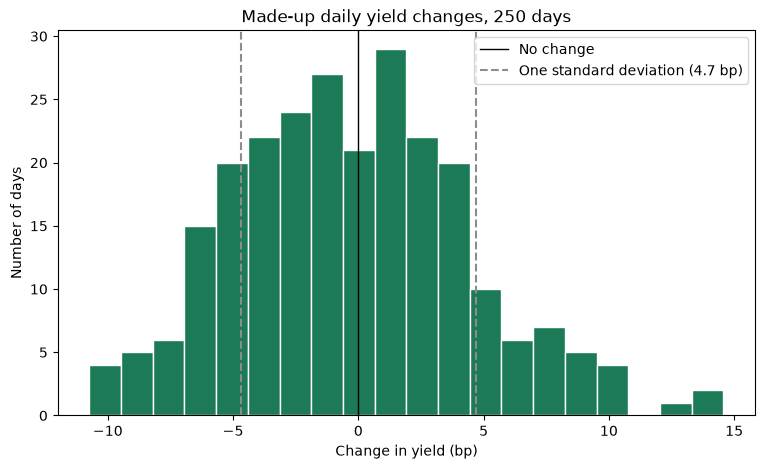

In [44]:
import matplotlib.pyplot as plt

# the size of a typical day: the standard deviation of the 250 changes
typical = daily_changes_bp.std()

fig, ax = plt.subplots(figsize=(9, 5))
# hist() counts how many days fall in each of 20 equal-width bins
ax.hist(daily_changes_bp, bins=20, color='#1c7a57', edgecolor='white')
# the solid line marks no change, and the dashed lines are one standard deviation either side
ax.axvline(0, color='black', linewidth=1, label='No change')
ax.axvline(-typical, color='#8c8c8c', linestyle='--', label=f'One standard deviation ({typical:.1f} bp)')
ax.axvline(typical, color='#8c8c8c', linestyle='--')
ax.set_title('Made-up daily yield changes, 250 days')
ax.set_xlabel('Change in yield (bp)')
ax.set_ylabel('Number of days')
ax.legend()
plt.show()

Most days sit close to 0 and few are far from it: the bell shape.

The dashed lines mark one standard deviation either side of zero, the 'typical' day.

Check it against the numbers above: the bars are centred near 0, and the dashed lines sit about 5 bp either side.

A price move can be measured in points or as a return.

Two kinds of return are common.

Q. QVNE closed at 98.50, 98.70, 98.40, 98.90, and 99.10 on five days. What was the simple return on each day?

In [45]:
qvne_week = np.array([98.50, 98.70, 98.40, 98.90, 99.10])

# np.diff() gives each value minus the one before it, so there is one fewer value than before
price_changes = np.diff(qvne_week)
print('Changes in points:', np.round(price_changes, 2))

# the simple return is the change divided by the previous price
# [:-1] is every price except the last: the 'previous' price for each change
simple_returns = price_changes / qvne_week[:-1]
print('Simple returns (%):', np.round(simple_returns * 100, 4))

Changes in points: [ 0.2 -0.3  0.5  0.2]
Simple returns (%): [ 0.203  -0.304   0.5081  0.2022]


On the first day the price rose 0.20 points, and 0.20 divided by 98.50 is 0.203 percent.

**Excel side by side.** With the prices in B2:B6, the change is `=B3-B2` and the simple return is `=B3/B2-1`, each filled down.

The second kind is the **log return**: the natural logarithm of today's price over yesterday's price.

The natural logarithm of a number is the power that e, about 2.718, must be raised to in order to reach that number.

NumPy writes it `np.log()` and Excel writes it `=LN()`.

Q. What was the log return on each day?

In [46]:
# [1:] is every price except the first: 'today' for each day, set over [:-1], 'yesterday'
log_returns = np.log(qvne_week[1:] / qvne_week[:-1])
print('Log returns (%):', np.round(log_returns * 100, 4))

Log returns (%): [ 0.2028 -0.3044  0.5068  0.202 ]


Almost the same as the simple returns for small moves: 0.2028 percent against 0.203 percent on the first day.

They are not identical.

The reason desks use log returns is what happens when the days are added up.

Q. What was the return over the whole week, and can the daily returns be added to get it?

In [47]:
# the whole week: last price over first price
week_ratio = qvne_week[-1] / qvne_week[0]

print('Whole week, simple return:', round(week_ratio - 1, 6))
print('Sum of the daily simple returns:', round(simple_returns.sum(), 6))
print('Whole week, log return:', round(np.log(week_ratio), 6))
print('Sum of the daily log returns:', round(log_returns.sum(), 6))

# np.exp() is e raised to a power, so it undoes np.log(). Subtract 1 to get back the simple return
print('Undo the log:', round(np.exp(log_returns.sum()) - 1, 6))

Whole week, simple return: 0.006091
Sum of the daily simple returns: 0.006094
Whole week, log return: 0.006073
Sum of the daily log returns: 0.006073
Undo the log: 0.006091


The log returns add up exactly: the sum of the four daily log returns is the log return of the week.

The simple returns do not: their sum is close to the weekly return but not equal to it.

The reason is that daily price ratios multiply, and a logarithm turns multiplying into adding.

That is why log returns are used when a series is stretched over many days.

The last line undoes the log with `np.exp()`, which is `=EXP()` in Excel, and lands back on the whole-week simple return.

## You Can Now

By the end of this notebook, you can:

* Turn a column of holdings into an array and calculate cost, coupon income, and current yield for every bond in one line
* Say why `*` repeats a list and multiplies an array
* Summarize a portfolio: totals, averages, the highest and lowest and which bond they belong to, and a face-weighted average
* Compare two results that have decimal points with `np.isclose()` and `np.allclose()`, and say why `==` is the wrong test for them
* Use the standard deviation, random numbers with a seed, and simple and log returns
* Spot a zero price before it becomes an `inf`

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

A second desk holds three different bonds.

Use what you learned above to answer its questions.

The issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">A</td><td align="left">6</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">BBB-</td><td align="left">10</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">B</td><td align="left">15</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Replace each `...` with your own code, then run the check cell under it.

Run the next cell first.

It imports NumPy and defines `check`, a small function that marks your answers.

It allows for tiny rounding differences in numbers with a decimal point.

In [48]:
import numpy as np


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    if isinstance(expected, np.ndarray) and expected.dtype.kind == 'f':
        # arrays of numbers: same shape, and every value within a small tolerance
        correct = np.shape(answer) == expected.shape and np.allclose(answer, expected)
    elif isinstance(expected, np.ndarray):
        # arrays of text: same shape and the same values
        correct = np.array_equal(answer, expected)
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)

### Exercise 1

Q. Create an array for the tickers, coupons, prices, and face held of the three bonds. Then work out the cost of every position in one line, and the total cost. Store the answers in **ex1_costs** and **ex1_total_cost**.

In [49]:
tickers = ...
coupons = ...
prices = ...
faces = ...

ex1_costs = ...
ex1_total_cost = ...

In [50]:
check('Exercise 1 costs', ex1_costs, np.array([1925000.0, 1250000.0, 522500.0]))
check('Exercise 1 total cost', ex1_total_cost, 3697500.0)

Exercise 1 costs: not attempted yet
Exercise 1 total cost: not attempted yet


### Exercise 2

Q. Work out the current yield of every bond, rounded to two decimal places. Find the ticker of the bond with the highest current yield using `np.argmax()`. Then find the face-weighted average coupon. Store the answers in **ex2_current_yields**, **ex2_highest_ticker**, and **ex2_weighted_coupon**.

In [51]:
ex2_current_yields = ...
ex2_highest_ticker = ...
ex2_weighted_coupon = ...

In [52]:
check('Exercise 2 current yields', ex2_current_yields, np.array([4.55, 5.0, 7.89]))
check('Exercise 2 highest ticker', ex2_highest_ticker, 'CLDB')
check('Exercise 2 weighted coupon', ex2_weighted_coupon, 5.1)

Exercise 2 current yields: not attempted yet
Exercise 2 highest ticker: not attempted yet
Exercise 2 weighted coupon: not attempted yet


### Exercise 3

A calculation that will be needed again belongs in a function.

Next month the same function runs on the new holdings, and nothing is typed a second time.

Q. Write a function `annual_income(faces, coupons)` that takes an array of face amounts and an array of annual coupons in percent, and returns the total annual coupon income as one number. The first line and the docstring are given. Replace the `...` in the body with your code, and end it with `return`.

Q. The income divided by the total face, times 100, is the face-weighted average coupon. Call your function on the three bonds, and use `np.isclose()` to test whether that figure agrees with **ex2_weighted_coupon**. Store the True or False in **ex3_agrees**.

In [53]:
def annual_income(faces, coupons):
    """
    Take an array of face amounts and an array of annual coupons in percent,
    and return the total annual coupon income as a single number.
    """
    ...


ex3_agrees = ...

In [54]:
# the check calls your function on the three bonds
check('Exercise 3 income', annual_income(np.array([2000000, 1250000, 500000]), np.array([4.375, 5.0, 8.25])), 191250.0)
check('Exercise 3 agrees', ex3_agrees, True)

Exercise 3 income: not attempted yet
Exercise 3 agrees: not attempted yet


### Exercise 4

CLDB closed at 104.50, 104.00, 104.25, and 105.00 on four days.

Q. Put the four closes in an array. Find the simple return on each of the three days, as a decimal, and store the three returns in **ex4_simple_returns**. Find the sum of the daily log returns and store it in **ex4_log_total**. Then find the sample standard deviation of the four closes and store it in **ex4_sample_std**.

In [55]:
ex4_simple_returns = ...
ex4_log_total = ...
ex4_sample_std = ...

In [56]:
check('Exercise 4 simple returns', ex4_simple_returns, np.array([-0.00478469, 0.00240385, 0.00719424]))
check('Exercise 4 log total', ex4_log_total, 0.00477328)
check('Exercise 4 sample standard deviation', ex4_sample_std, 0.42695628)

Exercise 4 simple returns: not attempted yet
Exercise 4 log total: not attempted yet
Exercise 4 sample standard deviation: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for code that gives the weighted average coupon of the three positions.

It gives you the code below.

It was written for this course in the style of an AI answer, and it has one bug.

Q. Read the code before you run it. What number do you expect? You worked out the face-weighted average coupon yourself in Exercise 2. Then run the code. Does it agree with you?

In [57]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
ai_coupons = np.array([4.375, 5.0, 8.25])
ai_prices = np.array([96.25, 100.0, 104.5])
ai_faces = np.array([2000000, 1250000, 500000])

# weight each coupon by its position in the portfolio
ex5_weighted_coupon = np.average(ai_coupons, weights=ai_prices)
print(f'The weighted average coupon is {round(ex5_weighted_coupon, 2)} percent')

The weighted average coupon is 5.93 percent


Q. Find the bug and fix the code in the cell above, so that **ex5_weighted_coupon** holds the right answer.

In [58]:
check('Exercise 5', ex5_weighted_coupon, 5.1)

Exercise 5: not yet. You have 5.929239401496259


## Congratulations!

You made it through the first half of NumPy.

At the top of this notebook a list could not multiply face by price.

Now one line gives you the cost, the income, and the current yield of every bond.

You found the highest yield and the bond it belongs to, worked out the average that matches the cash, and measured spread and returns.

That is real desk arithmetic, and you wrote every line of it.

Next is NumPy, Part 2.

You pick bonds out of an array by a condition, hold a table in one array, and price a bond from its cash flows with no loop at all.